# Walkthrough: from three public APIs to a variant classifier

This notebook runs the whole pipeline step by step, using the same functions as the CLI (`python -m vpe ...`).

1. Fetch one protein (TP53) from **UniProt**, its **AlphaFold** structure, and its **ClinVar** missense variants.
2. Turn every variant into numeric features.
3. Load the 42-gene panel and compare a **gene-held-out** split with a **random** split.
4. Compare with simple baselines (and AlphaMissense as a *reference*, not as a feature).

API responses are cached in `data/cache/`, so re-running is fast. The first run needs internet.

In [1]:
import os
from pathlib import Path

# run from the repository root so relative paths (data/, results/) work
if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from vpe.dataset import build_gene
from vpe.http import CachedSession
from vpe.model import cross_validate, make_models, score_baseline

session = CachedSession()
print("working directory:", Path.cwd())

working directory: /workspace/projects/variant-pathogenicity-explorer


## 1. One gene: TP53

In [2]:
tp53 = build_gene("TP53", session)
p = tp53.protein
print(f"UniProt {p.accession}: {p.name}, {p.length} residues")
print("AlphaFold model found:", tp53.structure is not None)
print(f"ClinVar labelled missense variants: {tp53.n_clinvar}, dropped (ref mismatch): {tp53.n_ref_mismatch}")
print("domains:", [d.description for d in p.domains()][:8])

UniProt P04637: Cellular tumor antigen p53, 393 residues
AlphaFold model found: True
ClinVar labelled missense variants: 374, dropped (ref mismatch): 0
domains: ['', 'TADI', 'TADII', 'Bipartite nuclear localization signal', 'Nuclear export signal', '[KR]-[STA]-K motif']


In [3]:
t = tp53.table
print(t["label"].value_counts().rename({1: "pathogenic/likely", 0: "benign/likely"}))
t[["protein_change", "classification", "plddt", "contacts_10A", "blosum62", "in_domain", "label"]].head(8)

label
pathogenic/likely    224
benign/likely        150
Name: count, dtype: int64


,protein_change,classification,plddt,contacts_10A,blosum62,in_domain,label
0,P4L,Likely benign,45.91,5.0,-3.0,0.0,0
1,P4Q,Likely benign,45.91,5.0,-1.0,0.0,0
2,D7E,Likely benign,39.38,6.0,2.0,0.0,0
3,P8L,Likely benign,39.34,6.0,-3.0,0.0,0
4,P8R,Likely benign,39.34,6.0,-2.0,0.0,0
5,V10I,Benign,45.91,6.0,3.0,0.0,0
6,V10L,Likely benign,45.91,6.0,1.0,0.0,0
7,S15C,Likely benign,61.88,7.0,-1.0,0.0,0


### Where are the variants?

Pathogenic variants cluster in the DNA-binding domain (residues ~100-290), where AlphaFold is confident (high pLDDT). Benign variants are more common in the disordered ends.

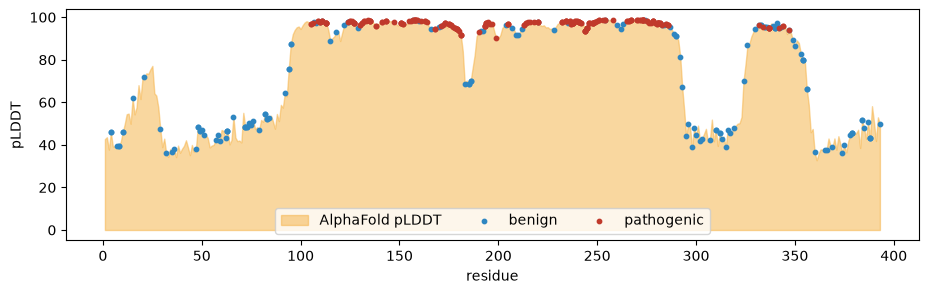

In [4]:
s = tp53.structure
fig, ax = plt.subplots(figsize=(11, 3))
ax.fill_between(np.arange(1, p.length + 1), s.plddt, color="#f5b041", alpha=0.5, label="AlphaFold pLDDT")
for lab, color, name in [(0, "#2e86c1", "benign"), (1, "#c0392b", "pathogenic")]:
    v = t[t.label == lab]
    ax.scatter(v["pos"], v["plddt"], s=10, color=color, label=name)
ax.set_xlabel("residue")
ax.set_ylabel("pLDDT")
ax.legend(loc="lower center", ncol=3)
plt.show()

## 2. The full panel (built by `python -m vpe build-dataset`)

In [5]:
df = pd.read_csv("data/processed/variants.csv")
print(f"{len(df)} variants, {df.gene.nunique()} genes, pathogenic fraction {df.label.mean():.3f}")
df.groupby("label")[["plddt", "contacts_10A", "blosum62"]].median().rename(index={0: "benign", 1: "pathogenic"})

8184 variants, 42 genes, pathogenic fraction 0.739


,plddt,contacts_10A,blosum62
label,,,
benign,75.06,10.0,0.0
pathogenic,94.62,20.0,-1.0


## 3. Gene-held-out vs random cross-validation

*Random split:* variants from the same gene are in both train and test, so the model can learn "this gene is mostly pathogenic".
*Gene-held-out split (GroupKFold):* every test gene is completely new to the model. This is the honest question: *does it work on a gene it has never seen?*

In [6]:
models = make_models()
rows = []
for name, model in models.items():
    for split in ["gene_held_out", "random"]:
        res = cross_validate(df, model, name, split=split)
        rows.append(res.summary(df["label"].to_numpy()))
cv = pd.DataFrame(rows)
cv[["model", "split", "roc_auc_mean", "roc_auc_sd", "pr_auc_mean"]].round(3)

,model,split,roc_auc_mean,roc_auc_sd,pr_auc_mean
0,logistic_regression,gene_held_out,0.847,0.053,0.931
1,logistic_regression,random,0.875,0.010,0.947
2,gradient_boosting,gene_held_out,0.859,0.040,0.939
3,gradient_boosting,random,0.920,0.006,0.967


In [7]:
piv = cv.pivot(index="model", columns="split", values="roc_auc_mean")
piv["inflation_from_leakage"] = piv["random"] - piv["gene_held_out"]
piv.round(3)

split,gene_held_out,random,inflation_from_leakage
model,,,
gradient_boosting,0.859,0.920,0.060
logistic_regression,0.847,0.875,0.027


## 4. Baselines (no training)

A model is only interesting if it beats simple single scores. AlphaMissense is a large published model; we show it as a **reference point** (an upper bar), not as a competitor and not as an input feature.

In [8]:
base = pd.DataFrame(
    [
        score_baseline(df, "blosum62", higher_is_pathogenic=False) | {"baseline": "BLOSUM62 (lower = worse swap)"},
        score_baseline(df, "plddt") | {"baseline": "AlphaFold pLDDT"},
        score_baseline(df, "alphamissense") | {"baseline": "AlphaMissense (reference)"},
    ]
)
base

,score,n,roc_auc,pr_auc,baseline
0,blosum62,8184,0.696618,0.839566,BLOSUM62 (lower = worse swap)
1,plddt,8184,0.798036,0.911102,AlphaFold pLDDT
2,alphamissense,8033,0.931256,0.971659,AlphaMissense (reference)


## Take-aways

* The gradient-boosting model beats each single feature on genes it has never seen.
* A random split looks better, but that extra score comes from leakage between variants of the same gene.
* AlphaMissense is still clearly better. It uses evolution data from many species, and this project does not.

Next step ideas: add conservation features (for example from multiple sequence alignments), map isoforms so fewer variants are dropped.